# 03 · Model Comparison (Q3)

**คำถามวิจัย Q3** — โมเดลใดจำแนกผู้ป่วย stroke ได้ดีที่สุดภายใต้ข้อมูลไม่สมดุล?

เราเปรียบเทียบ **6 โมเดล** จาก 4 ตระกูล 알고리즘 × 2 กลยุทธ์จัดการ imbalance:

| โมเดล | กลยุทธ์ imbalance |
|---|---|
| Logistic Regression | `class_weight='balanced'` |
| Logistic Regression | SMOTE (oversampling) |
| Random Forest | `class_weight='balanced_subsample'` |
| Random Forest | SMOTE |
| XGBoost | `scale_pos_weight` |
| LightGBM | `class_weight='balanced'` |

## 1. เตรียมข้อมูลและแยก train/test

In [1]:
import sys
from pathlib import Path

# ให้ import src ได้ไม่ว่าจะเปิด notebook จากโฟลเดอร์ไหน
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
print("Project root:", ROOT)

Project root: D:\Stroke Prediction Dataset\Stroke-Prediction-XAI


In [2]:
def show_figure(relative_path: str, width: int = 950):
    """แสดงรูปที่ pipeline สร้างไว้ใน reports/figures"""
    path = ROOT / "reports" / "figures" / relative_path
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print(f"[ไม่พบรูป] {path} — รัน `python -m src.run_pipeline` ก่อน")

In [3]:
from sklearn.model_selection import train_test_split
from src import config as cfg, data_loader as dl, models as mdl

clean = dl.basic_clean(dl.load_raw())
X, y = dl.split_features_target(clean)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=cfg.TEST_SIZE, stratify=y, random_state=cfg.RANDOM_STATE)

print(f"Train: {len(X_train):,} (stroke {int(y_train.sum())})")
print(f"Test : {len(X_test):,} (stroke {int(y_test.sum())})")
print("ใช้ stratify=y เพื่อรักษาสัดส่วนคลาสในทั้งสองชุด")

Train: 4,087 (stroke 199)
Test : 1,022 (stroke 50)
ใช้ stratify=y เพื่อรักษาสัดส่วนคลาสในทั้งสองชุด


## 2. ระเบียบวิธี: เลือก threshold อย่างถูกต้อง

ด้วยข้อมูลไม่สมดุล (4.87%) ค่า probability ที่โมเดลให้มักต่ำกว่า 0.5 เกือบทั้งหมด
→ การใช้ threshold = 0.5 แบบไม่คิด **ไม่ควรถือเป็นค่าเริ่มต้น**

ขั้นตอนที่ใช้:

1. **Out-of-Fold (OOF) predictions** — ใช้ `cross_val_predict` บน train เท่านั้น
2. หา threshold ที่ให้ **F1 สูงสุด** จาก OOF
3. `fit` โมเดลเต็มบน train ทั้งชุด
4. ประเมินบน **test set** ด้วย threshold นั้น (และรายงานผลที่ 0.5 เทียบกันด้วย)

> ทำไมต้อง OOF? ถ้าไปหา threshold บน test set โดยตรง = **data leakage**
> ผลที่ได้จะดูดีเกินจริงและเชื่อถือไม่ได้

⚠️ **ข้อควรเข้าใจให้ถูก**: threshold ที่ optimal สำหรับ F1 **ไม่ได้แปลว่า Recall
จะสูงขึ้นเสมอ** — มันคือการเลือก "จุด" บน Precision-Recall curve
ถ้าโมเดลถูกถ่วงน้ำหนักคลาสอยู่แล้ว (balanced / SMOTE) threshold 0.5 อาจให้
Recall สูงมากอยู่แล้ว การขยับขึ้นไปที่ F1-optimal จึงเป็นการ **แลก Recall
เพื่อเอา Precision** ไม่ใช่การเพิ่ม Recall เราจะดูตัวเลขจริงในหัวข้อ 7

## 3. โหลดผลลัพธ์จากการเปรียบเทียบโมเดล

In [4]:
RETRAIN = False  # ตั้งเป็น True ถ้าต้องการเทรนใหม่จริง ๆ (ใช้เวลาหลายนาที)

summary = pd.read_csv(cfg.TABLES_DIR / "q3_model_comparison.csv")
if RETRAIN or summary is None:
    result = mdl.compare_models(X_train, y_train, X_test, y_test, verbose=True)
    summary = result.summary

cols = ["model", "threshold", "recall_sensitivity", "precision", "f1",
        "pr_auc_average_precision", "roc_auc", "specificity", "accuracy"]
summary[cols]

,model,threshold,recall_sensitivity,precision,f1,pr_auc_average_precision,roc_auc,specificity,accuracy
0,LogReg (SMOTE),0.725,0.70,0.2035,0.3153,0.2786,0.8404,0.8591,0.8513
1,RandomForest (SMOTE),0.224,0.66,0.1310,0.2185,0.1501,0.7911,0.7747,0.7691
2,LogReg (class_weight=balanced),0.766,0.60,0.2239,0.3261,0.2594,0.8394,0.8930,0.8787
3,RandomForest (class_weight=balanced_subsample),0.286,0.54,0.1698,0.2584,0.1944,0.7981,0.8642,0.8483
4,XGBoost (scale_pos_weight),0.514,0.44,0.1719,0.2472,0.1568,0.7990,0.8909,0.8689
5,LightGBM (class_weight=balanced),0.091,0.44,0.1447,0.2178,0.1416,0.7757,0.8663,0.8454


## 4. เปรียบเทียบด้วยกราฟ

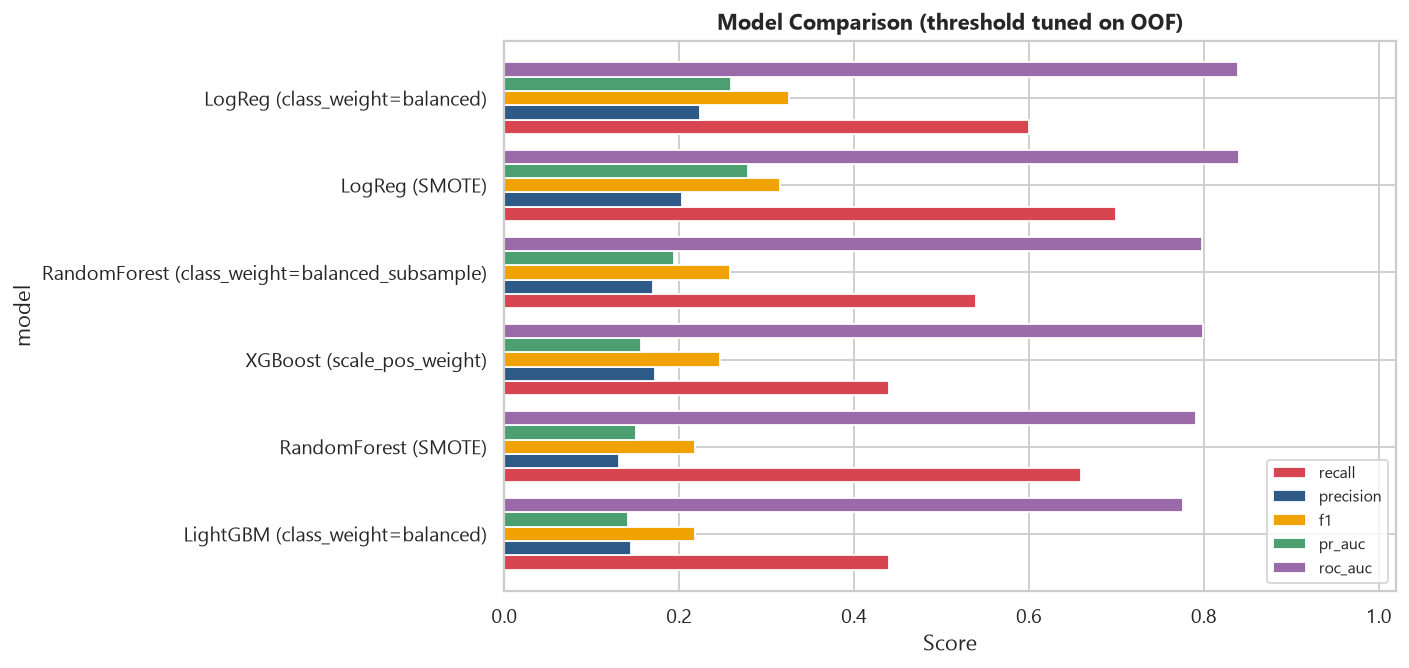

In [5]:
show_figure("model/10_model_comparison.png", 1000)

**อ่านกราฟ** — เราให้ความสำคัญกับ **Recall** และ **F1** มาก่อน
เพราะการ "พลาดผู้ป่วย" (False Negative) มีต้นทุนสูงกว่าการ "เตือนเกิน" (False Positive) มาก

## 5. Confusion Matrix — ดูเป็นจำนวนคน

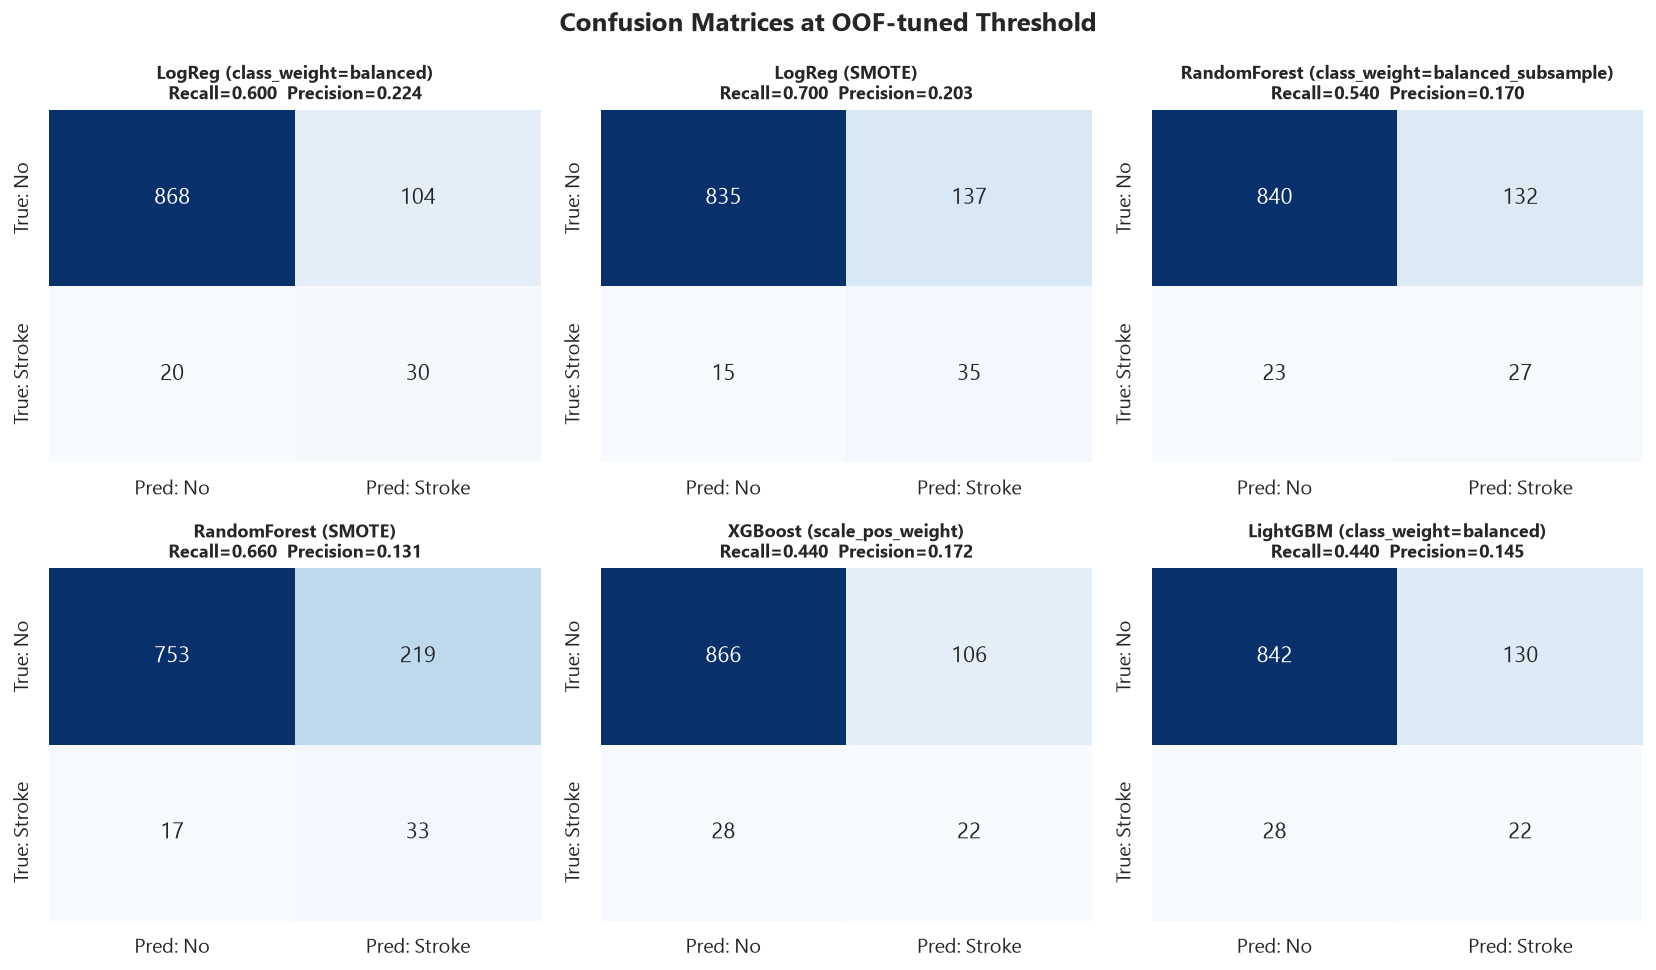

In [6]:
show_figure("model/11_confusion_matrices.png", 1150)

In [7]:
cm_tbl = pd.read_csv(cfg.TABLES_DIR / "q3_confusion_matrices.csv", index_col=0)
cm_tbl

,Unnamed: 1,Predicted: No Stroke,Predicted: Stroke
LogReg (class_weight=balanced),Actual: No Stroke,868,104
LogReg (class_weight=balanced),Actual: Stroke,20,30
LogReg (SMOTE),Actual: No Stroke,835,137
LogReg (SMOTE),Actual: Stroke,15,35
RandomForest (class_weight=balanced_subsample),Actual: No Stroke,840,132
RandomForest (class_weight=balanced_subsample),Actual: Stroke,23,27
RandomForest (SMOTE),Actual: No Stroke,753,219
RandomForest (SMOTE),Actual: Stroke,17,33
XGBoost (scale_pos_weight),Actual: No Stroke,866,106
XGBoost (scale_pos_weight),Actual: Stroke,28,22


In [8]:
# แสดง FN (ผู้ป่วยที่ถูกมองข้าม) ของแต่ละโมเดล — ยิ่งน้อยยิ่งดี
best_rows = summary.set_index("model")
fn_table = best_rows[["fn", "tp", "fp", "tn", "recall_sensitivity", "f1"]].copy()
fn_table["missing_rate_%"] = (fn_table["fn"] / (fn_table["fn"] + fn_table["tp"]) * 100).round(1)
fn_table.sort_values("fn")

,fn,tp,fp,tn,recall_sensitivity,f1,missing_rate_%
model,,,,,,,
LogReg (SMOTE),15,35,137,835,0.70,0.3153,30.0
RandomForest (SMOTE),17,33,219,753,0.66,0.2185,34.0
LogReg (class_weight=balanced),20,30,104,868,0.60,0.3261,40.0
RandomForest (class_weight=balanced_subsample),23,27,132,840,0.54,0.2584,46.0
XGBoost (scale_pos_weight),28,22,106,866,0.44,0.2472,56.0
LightGBM (class_weight=balanced),28,22,130,842,0.44,0.2178,56.0


## 6. Precision-Recall และ ROC Curve

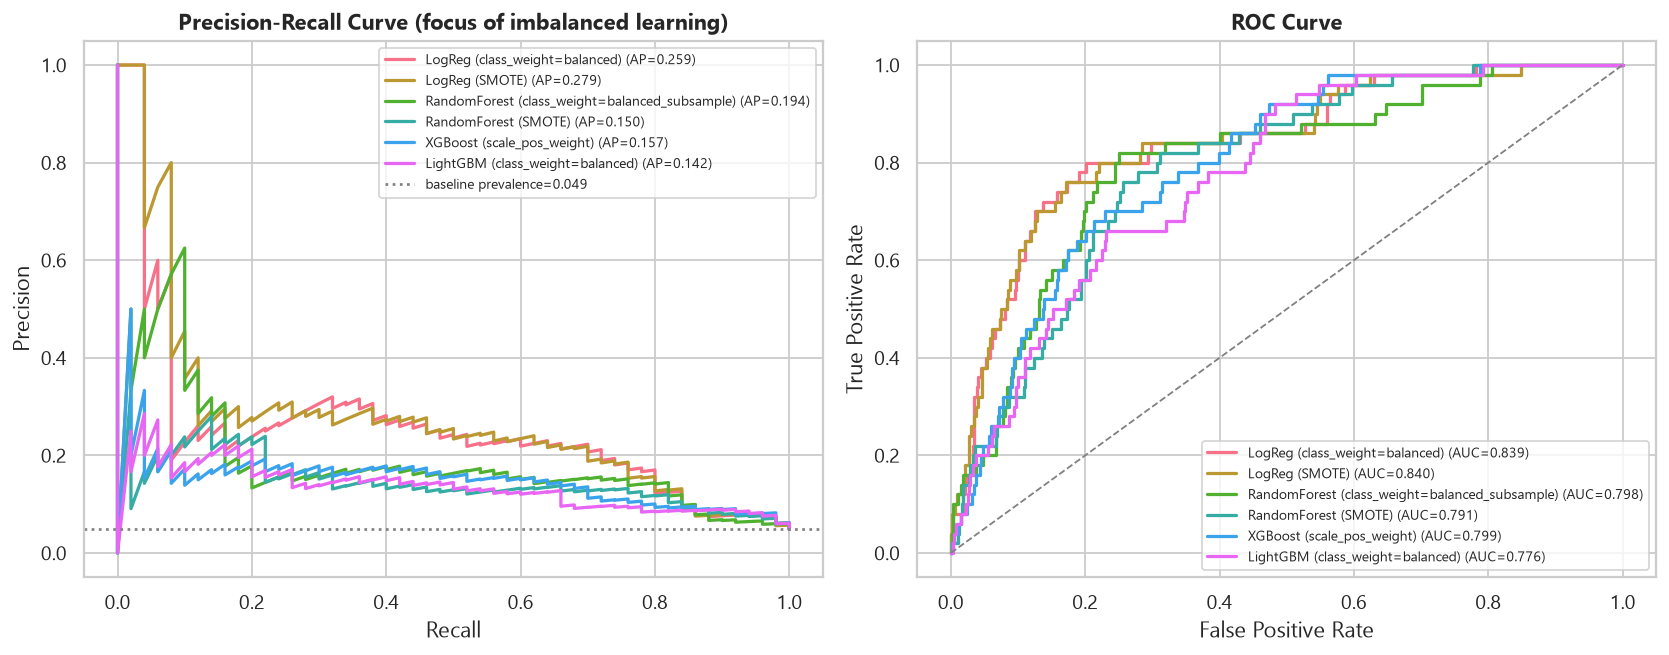

In [9]:
show_figure("model/12_pr_roc_curves.png", 1250)

**ทำไม PR Curve สำคัญกว่า ROC ที่นี่?**
ROC-AUC ใช้ทั้ง TPR และ FPR ซึ่ง FPR มีตัวหารเป็น TN ที่มีอยู่มหาศาล (4,860 ราย)
ทำให้ดูเหมือนได้เปรียบเสมอแม้โมเดลจะแย่ในคลาสบวก
ส่วน **PR-AUC (Average Precision)** โฟกัสที่คลาสบวกโดยตรง
จึงสะท้อนความสามารถจริงในการจับผู้ป่วยได้ดีกว่า

> เส้น baseline สีเทาในกราฟ PR = prevalence (0.049) ไม่ใช่ 0.5
> โมเดลที่ PR-AUC = prevalence ถือว่า "ไม่ดีไปกว่าการสุ่มเลย"

## 7. โมเดลที่ดีที่สุด — ขึ้นกับเกณฑ์ที่เลือก

In [10]:
def report(model_row, label):
    print(f"=== {label}: {model_row['model']} ===")
    print(f"  threshold = {model_row['threshold']:.3f}")
    for k in ["recall_sensitivity", "precision", "f1", "pr_auc_average_precision",
              "roc_auc", "specificity", "accuracy"]:
        print(f"  {k:28s} = {model_row[k]:.4f}")
    print(f"  เทียบกับ threshold 0.5: F1 {model_row['f1@0.5']:.4f} -> {model_row['f1']:.4f} "
          f"| Recall {model_row['recall@0.5']:.4f} -> {model_row['recall_sensitivity']:.4f}")
    print()

best_f1 = summary.sort_values(["f1", "recall_sensitivity"], ascending=False).iloc[0]
best_pr = summary.sort_values(["pr_auc_average_precision", "recall_sensitivity"], ascending=False).iloc[0]
best_recall = summary.sort_values(["recall_sensitivity", "f1"], ascending=False).iloc[0]

report(best_f1, "สมดุลที่สุด (F1 สูงสุด)")
report(best_pr, "โฟกัสคลาสบวก (PR-AUC สูงสุด)")
report(best_recall, "คัดกรองแบบเน้น Recall (Recall สูงสุด)")

=== สมดุลที่สุด (F1 สูงสุด): LogReg (class_weight=balanced) ===
  threshold = 0.766
  recall_sensitivity           = 0.6000
  precision                    = 0.2239
  f1                           = 0.3261
  pr_auc_average_precision     = 0.2594
  roc_auc                      = 0.8394
  specificity                  = 0.8930
  accuracy                     = 0.8787
  เทียบกับ threshold 0.5: F1 0.2305 -> 0.3261 | Recall 0.8000 -> 0.6000

=== โฟกัสคลาสบวก (PR-AUC สูงสุด): LogReg (SMOTE) ===
  threshold = 0.725
  recall_sensitivity           = 0.7000
  precision                    = 0.2035
  f1                           = 0.3153
  pr_auc_average_precision     = 0.2786
  roc_auc                      = 0.8404
  specificity                  = 0.8591
  accuracy                     = 0.8513
  เทียบกับ threshold 0.5: F1 0.2286 -> 0.3153 | Recall 0.8000 -> 0.7000

=== คัดกรองแบบเน้น Recall (Recall สูงสุด): LogReg (SMOTE) ===
  threshold = 0.725
  recall_sensitivity           = 0.7000
  precision    

### 7.1 ผลของ threshold — ไม่ได้เป็นไปในทิศทางเดียวกันทุกโมเดล

ตารางนี้เทียบ Recall/F1 ที่ **threshold 0.5** กับ **threshold ที่ tune จาก OOF**
ดูให้ดีว่า **ทิศทางของ Recall ต่างกันตามโมเดล** — เป็นบทเรียนสำคัญ

In [11]:
cmp = summary[["model", "threshold", "threshold_rule",
                "recall@0.5", "recall_sensitivity", "f1@0.5", "f1"]].copy()
cmp["recall_change"] = (cmp["recall_sensitivity"] - cmp["recall@0.5"]).round(4)
cmp["f1_change"] = (cmp["f1"] - cmp["f1@0.5"]).round(4)
display(cmp.sort_values("recall_change", ascending=False))

print("โมเดลที่ Recall 'เพิ่ม' หลัง tune:", list(cmp.loc[cmp["recall_change"] > 0, "model"]))
print("โมเดลที่ Recall 'ลด' หลัง tune :", list(cmp.loc[cmp["recall_change"] < 0, "model"]))

,model,threshold,threshold_rule,recall@0.5,recall_sensitivity,f1@0.5,f1,recall_change,f1_change
1,RandomForest (SMOTE),0.224,f1 on OOF,0.22,0.66,0.2115,0.2185,0.44,0.0070
3,RandomForest (class_weight=balanced_subsample),0.286,f1 on OOF,0.12,0.54,0.1714,0.2584,0.42,0.0870
5,LightGBM (class_weight=balanced),0.091,f1 on OOF,0.18,0.44,0.1935,0.2178,0.26,0.0243
4,XGBoost (scale_pos_weight),0.514,f1 on OOF,0.46,0.44,0.2527,0.2472,-0.02,-0.0055
0,LogReg (SMOTE),0.725,f1 on OOF,0.80,0.70,0.2286,0.3153,-0.10,0.0867
2,LogReg (class_weight=balanced),0.766,f1 on OOF,0.80,0.60,0.2305,0.3261,-0.20,0.0956


โมเดลที่ Recall 'เพิ่ม' หลัง tune: ['RandomForest (SMOTE)', 'RandomForest (class_weight=balanced_subsample)', 'LightGBM (class_weight=balanced)']
โมเดลที่ Recall 'ลด' หลัง tune : ['LogReg (SMOTE)', 'LogReg (class_weight=balanced)', 'XGBoost (scale_pos_weight)']


> **Insight Q3.2 — threshold คือการเลือก "จุด" บน PR curve ไม่ใช่ "การปรับให้ดีขึ้น"**
>
> - **โมเดลที่ยังไม่จัดการ imbalance** (RandomForest, LightGBM): ที่ 0.5 Recall ต่ำมาก
>   (0.12–0.22) เพราะ probability ของคลาสบวกถูกกดต่ำ → การ tune **ยก Recall ขึ้นมหาศาล**
> - **โมเดลที่ถ่วงน้ำหนักคลาสแล้ว** (LogReg balanced / SMOTE และ XGBoost ที่ใช้
>   `scale_pos_weight`): ที่ 0.5 Recall **สูงอยู่แล้ว** เพราะน้ำหนักของคลาสบวก
>   ดัน probability ขึ้น → การเลือกจุด F1-optimal จึง **"ลด" Recall เพื่อแลก Precision**
>
> ทั้งสองกรณีถูกต้องทั้งคู่ — มันคือการเลือกจุดบนเส้นโค้ง ตามต้นทุน FN:FP ที่เราเชื่อ
>
> ⚠️ **ข้อควรระวัง**: ถ้าต้องการ Recall สูงสุด *ไม่จำเป็น* ต้อง tune threshold เลย —
> โมเดลที่ถ่วงน้ำหนักคลาสแล้วที่ threshold 0.5 ให้ Recall สูงถึง **0.80**
> (จับผู้ป่วยได้ 40 จาก 50 ราย) โดยแลกกับ false positive ที่เพิ่มขึ้นมาก

> **ข้อสังเกตสำคัญ**: "โมเดลที่ดีที่สุด" **ไม่ใช่คำตอบเดียว**
> ขึ้นกับว่าเราให้น้ำหนักกับอะไร
>
> - ถ้าเน้น **F1** → เลือกตัวที่สมดุล Recall/Precision
> - ถ้าเน้น **PR-AUC** → เลือกตัวที่แยกคลาสบวกได้ดีที่สุดโดยรวม (เหมาะกับงานคัดกรอง)
> - ถ้าเน้น **Recall** → เลือกตัวที่พลาดผู้ป่วยน้อยที่สุด แต่จะเตือนเกินเยอะ
>
> การรายงาน **ทางเลือกที่แตกต่างกัน** อย่างตรงไปตรงมา เป็นส่วนสำคัญของงานวิเคราะห์
> ที่ดี เพราะผู้อ่านอาจมีต้นทุน FN/FP ไม่เหมือนเรา

## 8. สรุป Q3

**ผลลัพธ์ที่ได้ (จากการรัน pipeline)**

- โมเดลเชิงเส้น (**Logistic Regression**) ให้ผลดีที่สุดหรือใกล้เคียงดีที่สุดในชุดข้อมูลนี้
  เมื่อดูทั้ง F1, PR-AUC และ ROC-AUC — เป็นไปได้เพราะความสัมพันธ์ระหว่างฟีเจอร์กับ
  log-odds ของ stroke ค่อนข้างเป็นแบบเชิงเส้น/มอนอโทนิก (โดยเฉพาะอายุ)
- **Gradient boosting (XGBoost/LightGBM)** ไม่ได้ให้ผลดีกว่าในชุดข้อมูลนี้ เพราะ
  ข้อมูลมีเพียง ~4,000 แถวและคลาสบวกแค่ ~200 ราย โมเดลที่ซับซ้อนจึงมีแนวโน้ม overfit
- **การ tune threshold มีผลมาก แต่ทิศทางขึ้นกับโมเดล** — ดูหัวข้อ 7.1
  ไม่ควรสรุปว่า "tune แล้ว Recall จะเพิ่มเสมอ"
- **Accuracy เกือบเท่ากันทุกโมเดล (~77–88%)** ซึ่งพิสูจน์ว่า accuracy ไม่ใช่ตัวชี้วัดที่มีประโยชน์
  เพราะทุกโมเดลAccuracy สูง แต่ Recall ต่างกันเกือบสองเท่า
- **Class weighting vs SMOTE** ให้ผลใกล้เคียงกัน โดย SMOTE มักได้ Recall สูงขึ้น
  แต่ Precision ลดลง (แลกกัน) และมีข้อเสียคือสร้าง record สังเคราะห์ที่ตีความทางคลินิกไม่ได้

**ข้อจำกัดที่ต้องรายงาน**

- test set มีผู้ป่วยจริงเพียง 50 ราย → metric มีความแปรปรวนสูง
  (ผู้ป่วย 1 ราย = 2% ของ Recall) ควรดูช่วงความเชื่อมั่นจาก repeated CV ประกอบ
- ยังไม่มี external validation → ผลอาจไม่ generalize กับประชากรอื่น